# Comparing feature importance measures

Gini impurity measures class mixing, a split receives credit for reducing that mixing, and MDI adds the credit assigned to one feature:

$$
i(t)=1-\sum_{c=1}^{C}p_{c\mid t}^{,2},
\qquad
\Delta i(s,t)=i(t)-p_Li(t_L)-p_Ri(t_R),
\qquad
\operatorname{MDI}_j=\frac{1}{B}\sum_{b=1}^{B}\sum_{t\in T_b:v(t)=j}p(t)\Delta i(t).
$$

Here, $t$ is a tree node; $C$ is the number of classes; $p_{c\mid t}$ is the share of class $c$ in node $t.$ $s$ is a candidate split; $t_L,t_R$ are its child nodes; $p_L,p_R$ are their shares of the parent observations. $B$ is the number of trees; $T_b$ is tree $b$; $v(t)=j$ means node $t$ splits on feature $j$; $p(t)$ is the node sample share.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.ensemble import RandomForestClassifier

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.features.feature_importance import ClusteredFeatureImportanceMDA, ClusteredFeatureImportanceMDI, FeatureImportanceMDA, FeatureImportanceMDI, FeatureImportanceSFI, calculate_weighted_tau, conditional_predictive_impact, mdi_plus_importance, orthogonal_features

FIGURES = ROOT / "outputs" / "figures" / "14_feature_importance"
TABLES = ROOT / "outputs" / "tables" / "14_feature_importance"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

clusters = {
    "Consumer": ["Food", "Beer", "Hshld"],
    "Resources": ["Oil", "Coal", "Mines"],
    "Technology": ["Hardw", "Softw", "Chips"],
    "Finance": ["Banks", "Insur", "Fin"],
}
selected_features = [feature for values in clusters.values() for feature in values]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename("Market direction")
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame["Market direction"]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def forest(seed, trees=120, depth=5, leaf=10, features=1):
    return RandomForestClassifier(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, max_features=features, random_state=seed, n_jobs=1, bootstrap=True)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Public Industry Prediction Task

In [2]:
data_provenance = pd.DataFrame({
    "Field": ["Archive", "Provider", "Provider database vintage", "Return type", "Analysis start", "Analysis end", "Daily observations", "Industry portfolios", "Archive SHA256"],
    "Value": ["49_Industry_Portfolios_daily_CSV.zip", "Kenneth R. French Data Library", "202608 CRSP database", "Daily value-weighted return", str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), f"{len(industry_returns):,}", str(industry_returns.shape[1]), data_hash],
})
save_table(data_provenance, "data_provenance", "Fixed public observations used in Chapter 12.", "tab:chapter12-data-provenance", fit=True)
display(data_provenance)

public_task_summary = pd.DataFrame({
    "Quantity": ["Usable dates", "Predictors", "Lookback days", "Forecast step", "Positive target share", "First target date", "Last target date"],
    "Value": [len(public_x), public_x.shape[1], 5, 1, public_y.mean(), str(public_x.index.min().date()), str(public_x.index.max().date())],
})
save_table(public_task_summary, "public_task_summary", "Public descriptive prediction task for feature-importance comparison.", "tab:chapter12-public-task-summary", fit=False)
display(public_task_summary)

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Provider database vintage,202608 CRSP database
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Daily observations,"1,760"
7,Industry portfolios,49
8,Archive SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


,Quantity,Value
0,Usable dates,1755
1,Predictors,12
2,Lookback days,5
3,Forecast step,1
4,Positive target share,0.531624
5,First target date,2019-01-09
6,Last target date,2025-12-31


## Mean Decrease in Impurity

In [3]:
public_mdi = FeatureImportanceMDI(forest(1201)).compute(public_x, public_y)

## Mean Decrease in Predictive Score

Permutation importance is the average loss in held-out predictive score after one feature is randomly reordered:

$$
\operatorname{MDA}_j
=\frac{1}{K}\sum_{k=1}^{K}\left(S_k-S_{k,j}^{\pi}\right).
$$

Here, $K$ is the number of data folds; $k$ labels a fold; $S_k$ is its original score. $S_{k,j}^{\pi}$ is the score after feature $j$ is permuted in the held-out rows; $\pi$ denotes the random reordering. $\operatorname{MDA}_j$ is the mean score decrease, so a larger positive value gives more evidence that the fitted predictor used feature $j.$

In [4]:
public_mda = FeatureImportanceMDA(forest(1202), n_splits=5, random_state=1203).compute(public_x, public_y)

## Single-Feature Importance

Single-feature importance reports how well a model predicts when it is allowed to use only one feature:

$$
\operatorname{SFI}_j
=\frac{1}{K}\sum_{k=1}^{K}S\!\left(\widehat f_j^{(-k)},D_k\right).
$$

Here, $K$ is the number of folds; $D_k$ is held-out fold $k$; $\widehat f_j^{(-k)}$ is fitted on all other folds using only feature $j.$ $S(\widehat f,D)$ is the chosen predictive score on data $D$; $\operatorname{SFI}_j$ is the average score for feature $j$ alone.

,Industry,MDI,MDA log-loss decrease,SFI accuracy
0,Food,0.098615,0.002477,0.521368
8,Chips,0.097605,-0.000410,0.525356
4,Coal,0.096267,0.000722,0.533333
5,Mines,0.087848,-0.000534,0.533333
10,Insur,0.084105,-0.000256,0.511681
9,Banks,0.083611,-0.000568,0.503704
2,Hshld,0.083501,0.000517,0.507123
3,Oil,0.080059,-0.000327,0.530484
11,Fin,0.073610,-0.000489,0.528775
1,Beer,0.073472,0.000389,0.508262


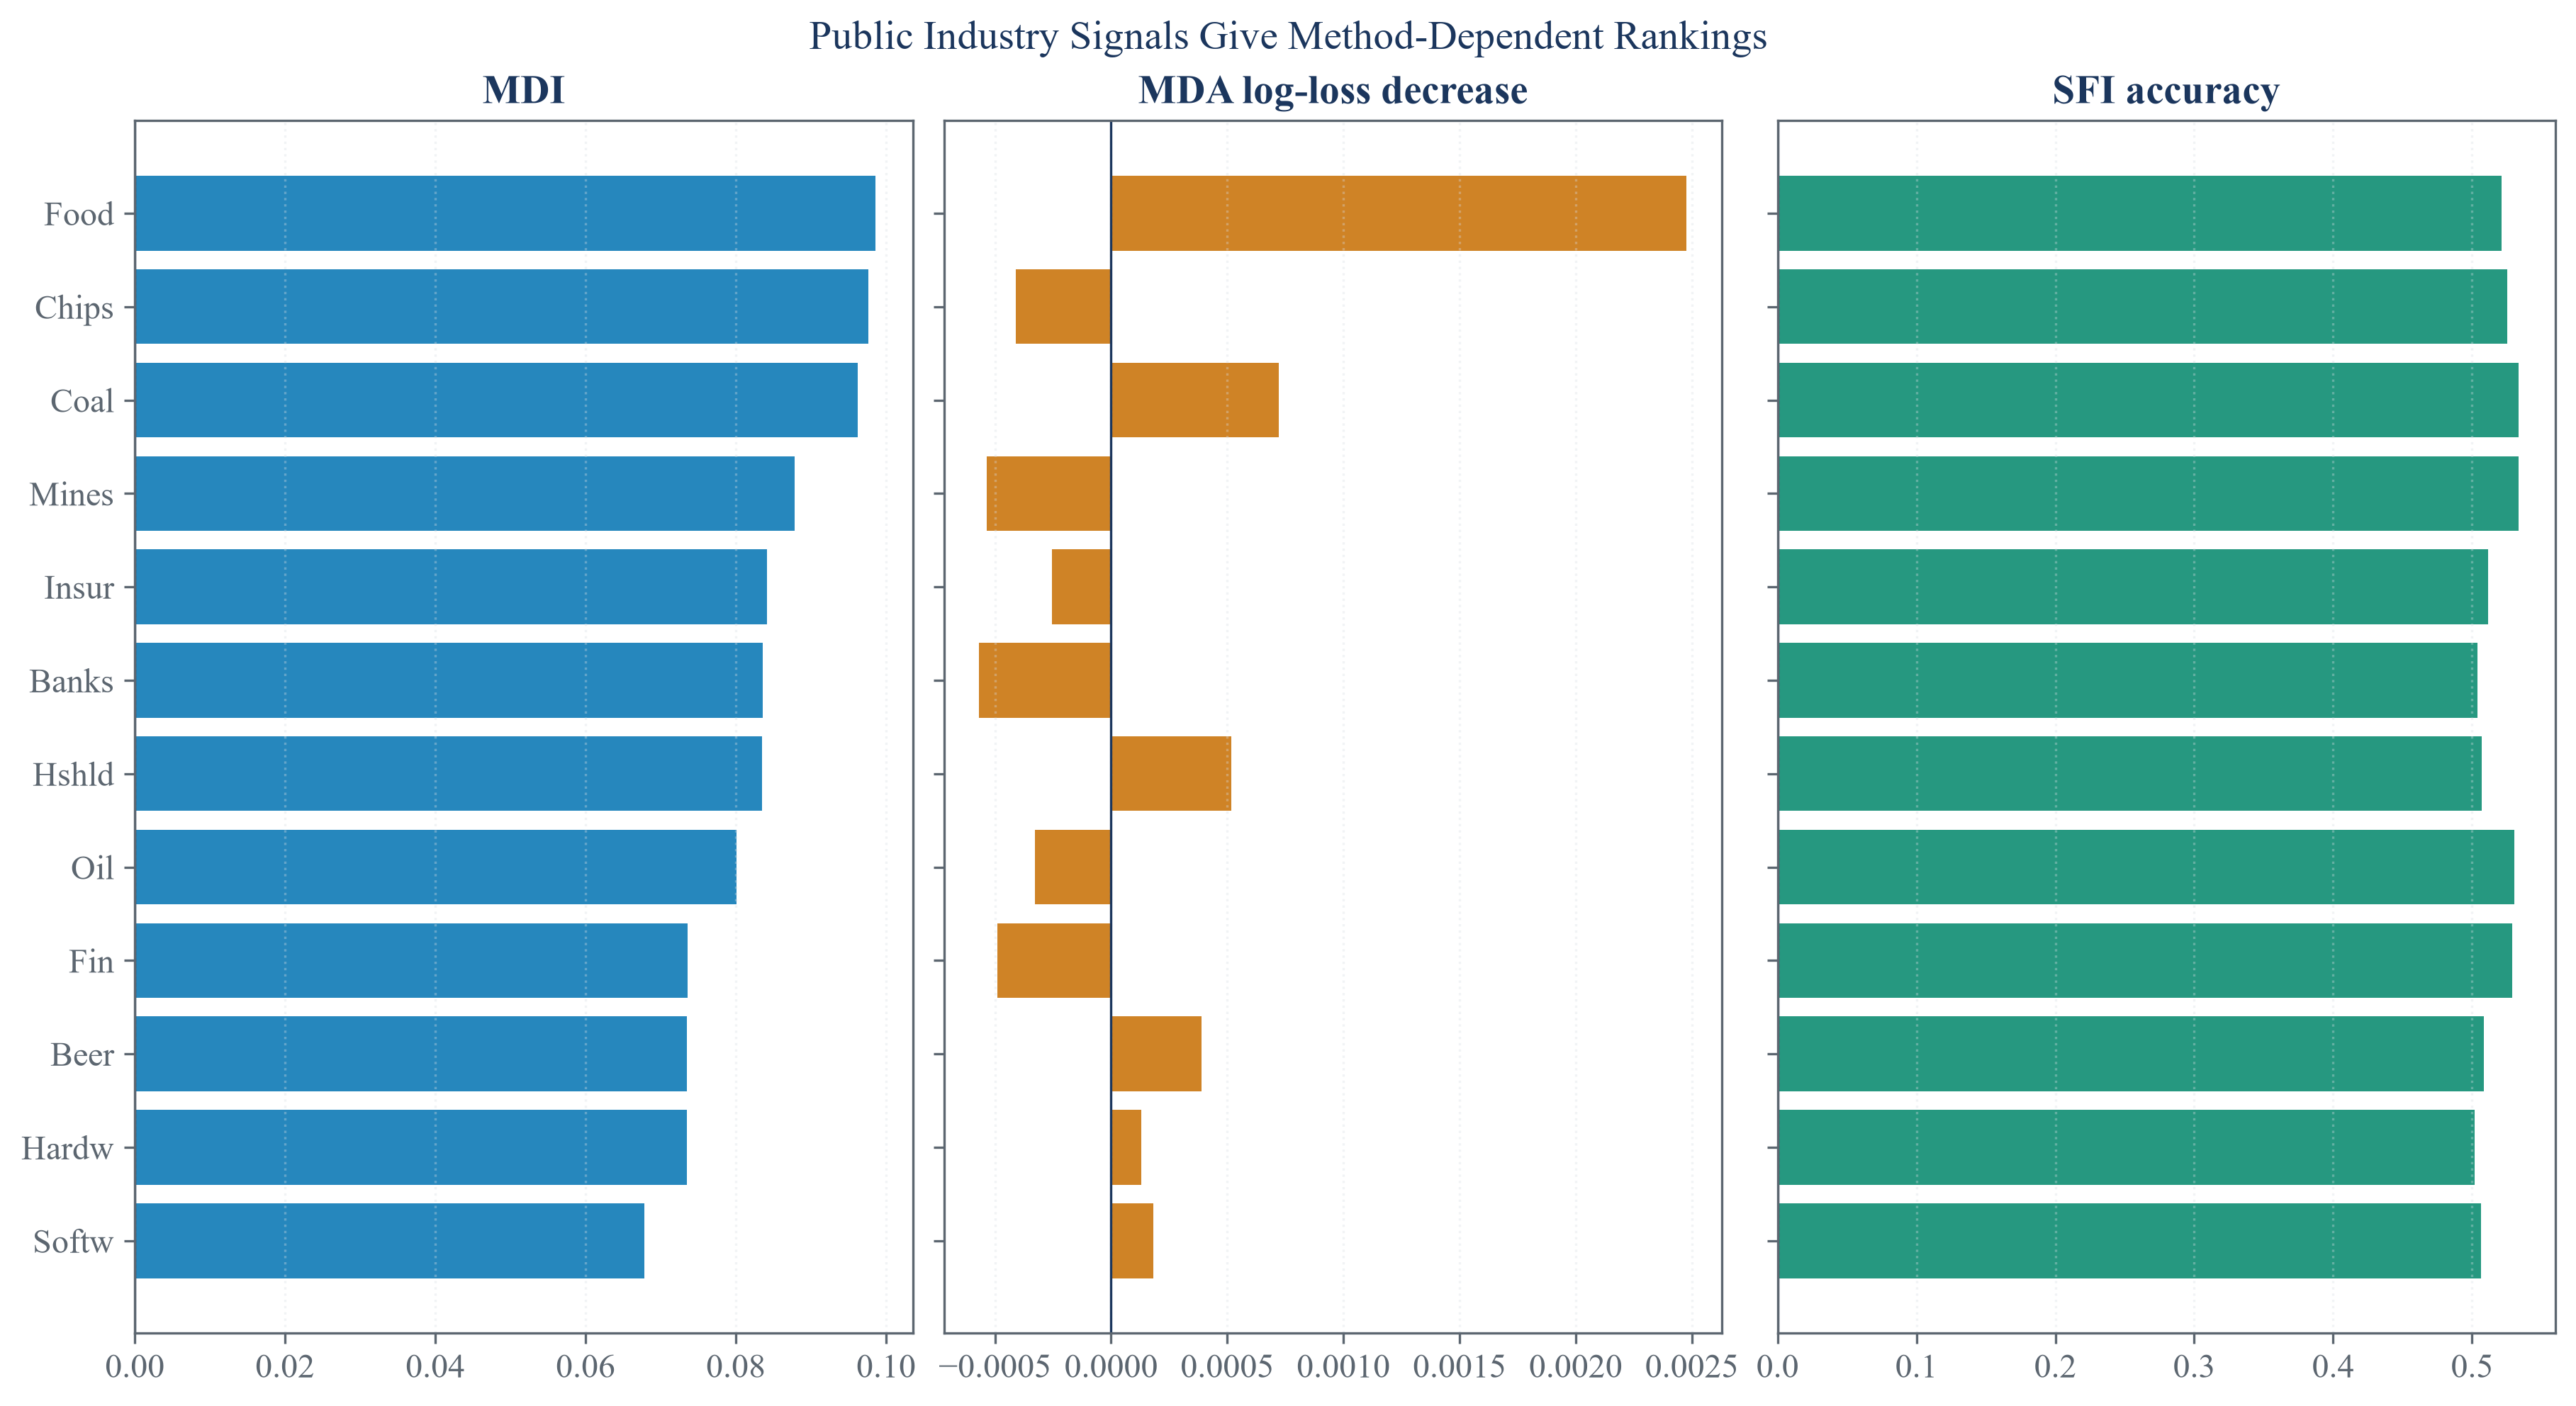

In [5]:
public_sfi = FeatureImportanceSFI(forest(1204), n_splits=5, scoring="accuracy").compute(public_x, public_y)
public_standard_importance = pd.concat([
    public_mdi["Mean"].rename("MDI"),
    public_mda["Mean"].rename("MDA log-loss decrease"),
    public_sfi["Mean"].rename("SFI accuracy"),
], axis=1).reset_index(names="Industry")
save_table(public_standard_importance, "public_standard_importance", "Three feature-importance summaries on the public descriptive task.", "tab:chapter12-public-standard-importance", fit=False)
display(public_standard_importance.sort_values("MDI", ascending=False).round(6))

order = public_standard_importance.sort_values("MDI")["Industry"]
figure, axes = plt.subplots(1, 3, figsize=(12.0, 6.5), sharey=True, constrained_layout=True)
columns = [("MDI", palette["cyan"]), ("MDA log-loss decrease", palette["amber"]), ("SFI accuracy", palette["green"])]
indexed = public_standard_importance.set_index("Industry").loc[order]
for axis, (column, color) in zip(axes, columns):
    axis.barh(indexed.index, indexed[column], color=color, alpha=0.85)
    axis.axvline(0, color=palette["text"], linewidth=0.8)
    axis.set_title(column)
    axis.grid(axis="x", alpha=0.35)
figure.suptitle("Public Industry Signals Give Method-Dependent Rankings")
figure.savefig(FIGURES / "public_standard_importance.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_standard_importance.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_standard_importance.png")))
plt.close(figure)

## Recovering relevance despite redundancy

The controlled label depends on two known signals, while two extra variables are noisy copies that can substitute for them:

$$
Y=\mathbf 1\!\left\{1.4Z_1+Z_2+0.8\varepsilon>0\right\},
\qquad
R_1=Z_1+0.08\eta_1,
\qquad
R_2=Z_2+0.08\eta_2.
$$

Here, $Y$ is the binary label; $\mathbf 1\{\cdot\}$ equals one when its condition is true; $Z_1,Z_2$ are independent signals. $R_1,R_2$ are redundant copies; $\varepsilon,\eta_1,\eta_2$ are independent standard-normal shocks; $1.4,1,0.8,0.08$ are fixed signal and noise scales.

,Feature,Role,Distinct values
0,Signal one,Direct signal,1200
1,Signal two,Direct signal,1200
2,Copy one,Redundant signal,1200
3,Copy two,Redundant signal,1200
4,Continuous noise,Noise,1200
5,Five-level noise,Noise,5


,Feature,MDI,MDA log-loss decrease,SFI accuracy,Role
0,Signal one,0.321299,0.142847,0.747500,Direct signal
1,Signal two,0.147391,0.060252,0.628333,Direct signal
2,Copy one,0.325812,0.115014,0.765000,Redundant signal
3,Copy two,0.152387,0.067806,0.630000,Redundant signal
4,Continuous noise,0.039519,0.001904,0.499167,Noise
5,Five-level noise,0.013592,0.000610,0.493333,Noise


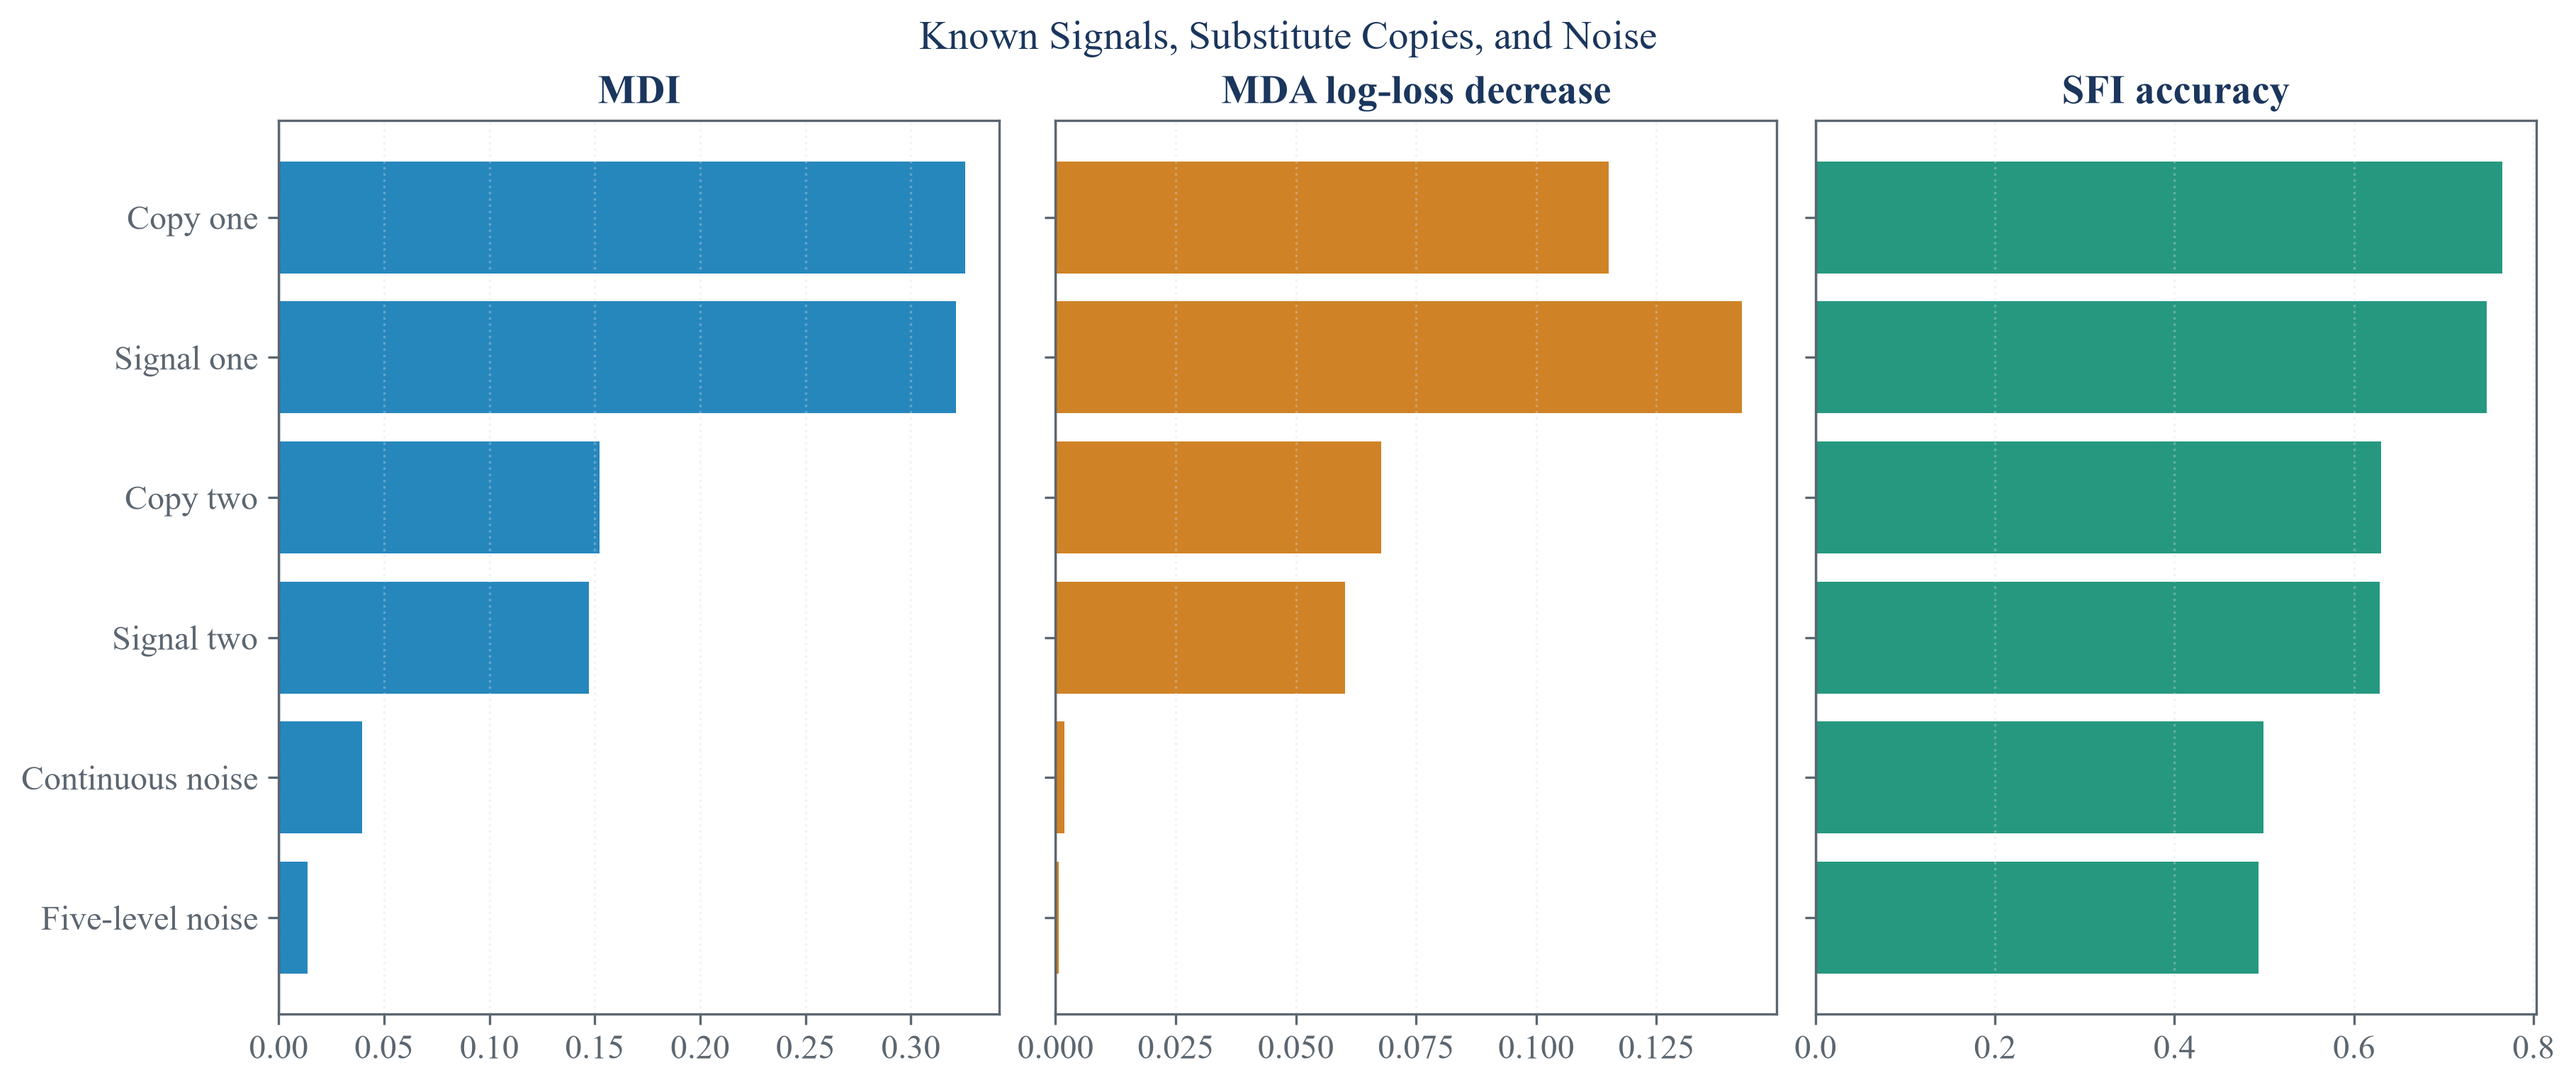

In [6]:
rng = np.random.default_rng(12001)
controlled_count = 1200
signal_one = rng.normal(size=controlled_count)
signal_two = rng.normal(size=controlled_count)
controlled_x = pd.DataFrame({
    "Signal one": signal_one,
    "Signal two": signal_two,
    "Copy one": signal_one + 0.08 * rng.normal(size=controlled_count),
    "Copy two": signal_two + 0.08 * rng.normal(size=controlled_count),
    "Continuous noise": rng.uniform(-3, 3, controlled_count),
    "Five-level noise": rng.integers(0, 5, controlled_count),
})
controlled_y = pd.Series((1.4 * signal_one + signal_two + 0.8 * rng.normal(size=controlled_count) > 0).astype(int))
controlled_mdi = FeatureImportanceMDI(forest(1221, trees=160, depth=6, leaf=8)).compute(controlled_x, controlled_y)
controlled_mda = FeatureImportanceMDA(forest(1222, trees=160, depth=6, leaf=8), n_splits=5, random_state=1223).compute(controlled_x, controlled_y)
controlled_sfi = FeatureImportanceSFI(forest(1224, trees=160, depth=6, leaf=8), n_splits=5, scoring="accuracy").compute(controlled_x, controlled_y)
controlled_design = pd.DataFrame({
    "Feature": controlled_x.columns,
    "Role": ["Direct signal", "Direct signal", "Redundant signal", "Redundant signal", "Noise", "Noise"],
    "Distinct values": [controlled_x[column].nunique() for column in controlled_x],
})
save_table(controlled_design, "controlled_standard_design", "Known-truth feature roles for the standard-method comparison.", "tab:chapter12-controlled-standard-design", fit=False)
display(controlled_design)

controlled_standard_importance = pd.concat([
    controlled_mdi["Mean"].rename("MDI"),
    controlled_mda["Mean"].rename("MDA log-loss decrease"),
    controlled_sfi["Mean"].rename("SFI accuracy"),
], axis=1).reset_index(names="Feature").merge(controlled_design[["Feature", "Role"]], on="Feature")
save_table(controlled_standard_importance, "controlled_standard_importance", "Standard importance measures on the known-truth design.", "tab:chapter12-controlled-standard-importance", fit=True)
display(controlled_standard_importance.round(6))

figure, axes = plt.subplots(1, 3, figsize=(12.0, 5.0), sharey=True, constrained_layout=True)
order = controlled_standard_importance.sort_values("MDI")["Feature"]
indexed = controlled_standard_importance.set_index("Feature").loc[order]
for axis, (column, color) in zip(axes, columns):
    axis.barh(indexed.index, indexed[column], color=color, alpha=0.85)
    axis.axvline(0, color=palette["text"], linewidth=0.8)
    axis.set_title(column)
    axis.grid(axis="x", alpha=0.35)
figure.suptitle("Known Signals, Substitute Copies, and Noise")
figure.savefig(FIGURES / "controlled_standard_importance.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "controlled_standard_importance.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "controlled_standard_importance.png")))
plt.close(figure)

## Tests

In [7]:
assert data_hash == EXPECTED_DATA_HASH
assert industry_returns.shape == (1760, 49)
assert public_x.shape == (1755, 12)
assert public_x.index.equals(public_y.index)
assert public_x.index.is_monotonic_increasing
assert not public_x.isna().any().any()
assert public_y.isin([0, 1]).all()
assert 0.45 < public_y.mean() < 0.60
assert public_mdi.shape == (12, 2)
assert np.isclose(public_mdi["Mean"].sum(), 1.0)
assert public_mdi["Mean"].ge(0).all()
assert public_mda.shape == (12, 2)
assert public_sfi.shape == (12, 2)
assert public_sfi["Mean"].between(0, 1).all()
assert public_standard_importance.shape == (12, 4)
assert controlled_x.shape == (1200, 6)
assert controlled_y.isin([0, 1]).all()
assert controlled_standard_importance.shape == (6, 5)
assert controlled_mdi.loc[["Signal one", "Signal two", "Copy one", "Copy two"], "Mean"].sum() > 0.90
assert controlled_mda.loc[["Signal one", "Signal two", "Copy one", "Copy two"], "Mean"].min() > 0.04
assert controlled_mda.loc[["Continuous noise", "Five-level noise"], "Mean"].max() < 0.02
assert controlled_sfi.loc[["Signal one", "Signal two", "Copy one", "Copy two"], "Mean"].min() > controlled_sfi.loc[["Continuous noise", "Five-level noise"], "Mean"].max() + 0.10
assert (FIGURES / "public_standard_importance.pdf").is_file()
assert (FIGURES / "controlled_standard_importance.pdf").is_file()
assert (TABLES / "public_standard_importance.tex").is_file()
assert (TABLES / "controlled_standard_importance.tex").is_file()